# Tendencia de clustering en los 144 segmentos de las fichas (región × sexo × edad × sección) · Hopkins y VAT

**Proyecto:** Hackathon INE 2026 · Reto 1 · Perfiles ciudadanos de participación.
Complementa `tendencia_clustering.ipynb`, `tendencia_clustering_forma.ipynb` y `tendencia_clustering_segmentos.ipynb`.

## Pregunta que responde
Las [fichas](../reports/sociodemografico/fichas_dos_perfiles_por_region.md) proponen **dos perfiles por región**, obtenidos agrupando **144 segmentos** (48 por región: 2 sexos × 8 grupos de edad × 3 tipos de sección), cada uno descrito por su participación en las 6 elecciones. Los otros notebooks no probaron esa tabla: el primero usa 1,458 unidades con entidad y el tercero los 164 segmentos de `perfiles_sexo_edad`. Aquí se aplica Hopkins y VAT **a la misma tabla de las fichas**.

## Qué se puede y qué no se puede probar con esta tabla
La edad viene en solo 8 grupos, así que **no se puede comprobar si la participación es continua a lo largo de la edad** (eso lo hace el notebook de los 164 segmentos, con edad simple). Lo que sí se puede preguntar es:
1. ¿Hay estructura **más allá** de un gradiente por edad, con el sexo y la sección desplazándolo?
2. ¿Distingue la **silhouette** (el criterio con el que las fichas eligieron k = 2) una tabla real de una sin grupos?

## Nulos (referencias sin grupos)
- **`gauss`**: nube gaussiana con la misma media y covarianza.
- **`perm`**: columnas permutadas.
- **`suave` (nulo de gradiente suave, el principal).** Es el análogo del nulo de curva del notebook de los 164 segmentos. Por cada elección se ajusta un modelo por mínimos cuadrados: un **polinomio de grado 4 en la edad por sexo** más un **efecto de la sección** (y de la región en el control conjunto). Se generan 144 puntos nuevos sobre ese ajuste con ruido igual al residuo. Es una población que **por construcción es un gradiente continuo por edad** (con el sexo y la sección desplazándolo), sin ninguna estructura adicional.
- **`celdas` (nulo más estricto).** Igual, pero el efecto de cada combinación sexo × grupo de edad es libre (16 medias en lugar de un polinomio). Conserva cualquier forma que tengan las medias por edad y sexo, incluso saltos entre grupos. Lo que mide `delta_celdas` es si hay estructura **más allá de sexo × edad + sección**.

## Dos modelos de ruido en los nulos `suave` y `celdas`
- **Independiente** (el que se fijó antes de ejecutar): ruido normal con la desviación del residuo de cada elección, sin relación entre elecciones.
- **Con covarianza** (se agregó **después de ver el primer resultado**; sufijo `_cov`): ruido normal con la **covarianza completa** del residuo. Motivo: los residuos de las 6 elecciones están muy correlacionados, y el ruido independiente los esparce en todas las direcciones por igual; la tabla real queda entonces más "delgada" que el nulo y Hopkins sube sin que haya grupos. Se explica con los resultados en la sección 4.

## Qué se mide
- **Hopkins** con los tres nulos (200 repeticiones; con 48 puntos por región `m = 10`, y `m = 5` como sensibilidad).
- **Silhouette de k = 2** (algoritmo y escala de las fichas) frente a su distribución en los nulos `gauss` y `suave`.
- **Qué ordena los segmentos:** varianza explicada por edad, sexo y sección, y qué tanto reproduce el perfil publicado una regla de solo edad.
- **VAT** con los nulos y con el orden VAT contra la edad.

## Reglas de decisión (fijadas antes de ejecutar, con el ruido independiente; por región)
- **Sin estructura más allá del gradiente:** `delta_suave` < 0.05 **y** la silhouette real no supera el percentil 95 de la silhouette en el nulo `suave`.
- **Estructura más allá del gradiente:** `delta_suave` > 0.10 **y** la silhouette real supera ese percentil 95.
- **Ambiguo:** cualquier otro caso.

Los resultados con ruido de covarianza completa se reportan como sensibilidad y **no sustituyen** el veredicto formal.

## Alcance
Entra: Hopkins, silhouette frente a nulos, varianza explicada y VAT sobre la tabla de las fichas. **No entra**: el agrupamiento en sí, ni la entidad (la tabla ya está agregada por región), ni causas.

## Índice
1. Entorno · 2. Carga y validación · 3. Funciones y nulos · 4. Hopkins · 5. Silhouette frente a los nulos · 6. Qué ordena los segmentos · 7. Imágenes VAT · 8. Autopruebas · 9. Conclusiones

## 1. Entorno

In [1]:
import json, platform
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score as ari, normalized_mutual_info_score as nmi

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'reports/sociodemografico').exists())
SEGS = ROOT / 'reports/sociodemografico/perfiles_segmentos.csv'
METO = ROOT / 'reports/sociodemografico/metodologia.json'
MASTER = ROOT / 'data/processed/civia_dataset_maestro_municipal_2009_2024_con_region.csv'
OUT = ROOT / 'reports/local/tendencia_fichas'
OUT.mkdir(parents=True, exist_ok=True)

YEARS = [2009, 2012, 2015, 2018, 2021, 2024]
COLS = [f'participacion_{y}' for y in YEARS]
REGIONS = ['norte', 'centro', 'sur']
AGES = ['18-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75-84', '85+']
REPS = 200          # repeticiones de Hopkins
NDRAW = 50          # realizaciones de cada nulo en Hopkins
NDRAW_SIL = 200     # realizaciones de cada nulo para la silhouette
GRADO = 4           # grado del polinomio del nulo suave

print(f'Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · '
      f'scipy {scipy.__version__} · scikit-learn {sklearn.__version__} · matplotlib {matplotlib.__version__}')

Python 3.14.8 · numpy 2.5.4 · pandas 3.1.0 · scipy 1.18.1 · scikit-learn 1.9.1 · matplotlib 3.11.2


## 2. Carga y validación
Se lee `perfiles_segmentos.csv`, que contiene la tabla exacta que se agrupó (participación en % por segmento y elección, y el perfil A o B asignado). Antes de analizar se comprueba que es la misma matriz y el mismo agrupamiento que `scripts/perfiles_sociodemograficos.py`:
1. 144 filas, 48 por región, sin vacíos, con todas las combinaciones de sexo × edad × sección.
2. Con el algoritmo elegido por región (`metodologia.json`), la silhouette de k = 2 coincide y el agrupamiento coincide con el perfil publicado (ARI = 1).
3. Una celda coincide con el dataset maestro local (si está disponible).

In [2]:
def estimator(name, k, seed=SEED):
    """Mismos estimadores que scripts/perfiles_sociodemograficos.py."""
    if name == 'kmeans':
        return KMeans(n_clusters=k, n_init=30, random_state=seed)
    return AgglomerativeClustering(n_clusters=k, linkage='ward')


seg = pd.read_csv(SEGS).set_index(['region', 'sexo', 'grupo_edad', 'tipo_seccion'])
meto = {m['region']: m for m in json.loads(METO.read_text())['modelos_elegidos']}
algoritmo = seg.groupby('region').algoritmo.first().to_dict()
assert len(seg) == 144 and seg[COLS].notna().all().all()
assert seg.groupby('region').size().eq(48).all()
assert set(seg.index.get_level_values('grupo_edad')) == set(AGES)

frames = {r: seg.xs(r, level='region', drop_level=False) for r in REGIONS}
Zs = {r: StandardScaler().fit_transform(f[COLS].values) for r, f in frames.items()}   # escala por región, como en las fichas
for r in REGIONS:
    lab = estimator(algoritmo[r], 2).fit_predict(Zs[r])
    sil = silhouette_score(Zs[r], lab)
    assert abs(sil - meto[r]['silhouette']) < 1e-6, (r, sil, meto[r]['silhouette'])
    assert ari(lab, frames[r].perfil) == 1.0, (r, ari(lab, frames[r].perfil))
print('Silhouette y agrupamiento con k=2 coinciden con las fichas en las tres regiones:', algoritmo)

if MASTER.exists():
    m = pd.read_csv(MASTER, encoding='utf-8-sig', usecols=['anio', 'region', 'sexo', 'grupo_edad', 'tipo_seccion', 'si_votaron', 'no_votaron'])
    m = m[(m.anio == 2009) & (m.region == 'norte') & (m.sexo.str.lower() == 'hombre') & (m.grupo_edad == '18-24') & (m.tipo_seccion.str.lower() == 'mixta')]
    p = 100 * m.si_votaron.sum() / (m.si_votaron.sum() + m.no_votaron.sum())
    assert abs(p - seg.loc[('norte', 'hombre', '18-24', 'mixta'), 'participacion_2009']) < 1e-6
    print(f'Celda norte, hombre, 18-24, mixta, 2009 coincide con el maestro: {p:.3f} %')
else:
    print('Maestro no encontrado; se omite la comparación con el dataset original.')

# casos: tres regiones (análisis A) y las 144 juntas (control B, sin la región como variable)
cases = {**frames, 'conjunto': seg}
Zs['conjunto'] = StandardScaler().fit_transform(seg[COLS].values)
pd.DataFrame({'segmentos': {r: len(f) for r, f in cases.items()}, 'algoritmo fichas': {**algoritmo, 'conjunto': '-'}})

Silhouette y agrupamiento con k=2 coinciden con las fichas en las tres regiones: {'centro': 'ward', 'norte': 'kmeans', 'sur': 'kmeans'}


Celda norte, hombre, 18-24, mixta, 2009 coincide con el maestro: 31.793 %


,segmentos,algoritmo fichas
norte,48,kmeans
centro,48,ward
sur,48,kmeans
conjunto,144,-


## 3. Funciones y nulos
`hopkins` y `vat` son las mismas de los otros notebooks. `ajusta(...)` es el modelo de los nulos `suave` y `celdas` (ver la sección "Nulos" arriba): una matriz de diseño por mínimos cuadrados, con ruido igual al residuo del ajuste.

In [3]:
def hopkins(X, m=None, reps=REPS, seed=SEED):
    """Estadístico de Hopkins: devuelve (media, desviación estándar) en `reps` repeticiones.

    X: matriz (n, d). m: tamaño de muestra (por defecto 10 % de n, mínimo 10).
    """
    rng = np.random.default_rng(seed)
    n, dim = X.shape
    m = m or max(10, n // 10)
    tree = cKDTree(X)
    lo, hi = X.min(0), X.max(0)
    hs = []
    for _ in range(reps):
        w = tree.query(X[rng.choice(n, m, replace=False)], k=2)[0][:, 1]   # vecino más cercano distinto de sí mismo
        u = tree.query(rng.uniform(lo, hi, (m, dim)), k=1)[0]
        hs.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(hs)), float(np.std(hs))


def vat(X):
    """Matriz de distancias reordenada (VAT): devuelve (matriz n×n, orden de filas)."""
    D = squareform(pdist(X))
    n = len(D)
    first = int(np.unravel_index(D.argmax(), D.shape)[0])
    order, rest = [first], np.ones(n, bool)
    rest[first] = False
    near = D[first].copy()
    for _ in range(n - 1):
        j = int(np.argmin(np.where(rest, near, np.inf)))
        order.append(j)
        rest[j] = False
        near = np.minimum(near, D[j])
    return D[np.ix_(order, order)], np.array(order)


def veredicto(h, delta):
    """Misma regla heurística de los otros notebooks (umbrales exploratorios)."""
    if h > 0.75 and delta > 0.10: return 'clara'
    if h > 0.60 and delta > 0.05: return 'moderada'
    return 'sin evidencia'


def nulos(X, seed=SEED):
    """Referencias sin grupos: gaussiana con igual media/covarianza y columnas permutadas."""
    rng = np.random.default_rng(seed)
    return {'gauss': rng.multivariate_normal(X.mean(0), np.cov(X.T), len(X)),
            'perm': np.column_stack([rng.permutation(c) for c in X.T])}


def diseno(frame, tipo):
    """Matriz de diseño. 'suave': polinomio de grado GRADO en la edad por sexo; 'celdas': una media por sexo × grupo de edad.
    En ambos casos más el efecto de la sección (y de la región si el caso incluye varias)."""
    sexo = frame.index.get_level_values('sexo')
    edad = frame.index.get_level_values('grupo_edad').map(AGES.index).to_numpy()
    x = (edad - 3.5) / 3.5
    cols = []
    for s in ('hombre', 'mujer'):
        is_s = (sexo == s).astype(float)
        if tipo == 'celdas':
            cols += [is_s * (edad == a) for a in range(len(AGES))]
        else:
            cols += [is_s * x ** p for p in range(GRADO + 1)]
    sec = frame.index.get_level_values('tipo_seccion')
    cols += [(sec == s).astype(float) for s in ('mixta', 'rural')]
    reg = frame.index.get_level_values('region')
    cols += [(reg == r).astype(float) for r in ('centro', 'sur') if len(set(reg)) > 1]
    return np.column_stack(cols)


def ajusta(Z, frame, tipo):
    """Valores ajustados y desviación del residuo por elección (con corrección por grados de libertad)."""
    D = diseno(frame, tipo)
    beta = np.linalg.lstsq(D, Z, rcond=None)[0]
    mu = D @ beta
    gl = len(Z) - np.linalg.matrix_rank(D)
    return mu, np.sqrt(((Z - mu) ** 2).sum(0) / gl)


def ajusta_cov(Z, frame, tipo):
    """Valores ajustados y covarianza del residuo entre elecciones (con corrección por grados de libertad)."""
    D = diseno(frame, tipo)
    mu = D @ np.linalg.lstsq(D, Z, rcond=None)[0]
    return mu, (Z - mu).T @ (Z - mu) / (len(Z) - np.linalg.matrix_rank(D))


def nulo_modelo(mu, s, rng):
    """Conjunto nuevo sobre el ajuste. `s` es la desviación del residuo por elección (ruido independiente)
    o la matriz de covarianza del residuo (ruido con la correlación entre elecciones)."""
    if s.ndim == 2:
        return mu + rng.multivariate_normal(np.zeros(len(s)), s, len(mu))
    return mu + rng.normal(size=mu.shape) * s


modelos = {(c, t): ajusta(Zs[c], f, t) for c, f in cases.items() for t in ('suave', 'celdas')}
modelos_cov = {(c, t): ajusta_cov(Zs[c], f, t) for c, f in cases.items() for t in ('suave', 'celdas')}
print('Desviación media del residuo por elección (los datos estandarizados tienen desviación 1):')
pd.DataFrame({t: {c: modelos[(c, t)][1].mean() for c in cases} for t in ('suave', 'celdas')}).round(3)

Desviación media del residuo por elección (los datos estandarizados tienen desviación 1):


,suave,celdas
norte,0.176,0.157
centro,0.179,0.156
sur,0.173,0.158
conjunto,0.191,0.172


## 4. Hopkins
Con 48 puntos por región, `m = 10` es ≈21 % de n (por encima del 10 % habitual), por eso se agrega `m = 5` como sensibilidad. Para cada nulo de modelo se promedian `NDRAW` realizaciones y se reporta la desviación **entre realizaciones**. `delta_suave` y `delta_celdas` son `H_real` menos el Hopkins de cada nulo (ruido independiente, el de las reglas). Las columnas `_cov` repiten los dos nulos con ruido de covarianza completa (sensibilidad agregada después del primer resultado).

In [4]:
def h_modelo(mu, sd, m, ndraw=NDRAW):
    """Hopkins medio sobre `ndraw` realizaciones de un nulo de modelo; devuelve (media, desviación entre realizaciones)."""
    rng = np.random.default_rng(SEED)
    hs = [hopkins(nulo_modelo(mu, sd, rng), m=m, reps=20, seed=i)[0] for i in range(ndraw)]
    return float(np.mean(hs)), float(np.std(hs))


rows = []
for case, frame in cases.items():
    Z = Zs[case]
    for m in (None, 5):
        h, sd_ = hopkins(Z, m=m)
        nul = nulos(Z)
        hg, hp = hopkins(nul['gauss'], m=m)[0], hopkins(nul['perm'], m=m)[0]
        hs, ss = h_modelo(*modelos[(case, 'suave')], m=m)
        hc, sc = h_modelo(*modelos[(case, 'celdas')], m=m)
        hsv, hcv = h_modelo(*modelos_cov[(case, 'suave')], m=m)[0], h_modelo(*modelos_cov[(case, 'celdas')], m=m)[0]
        rows.append({'caso': case, 'm': m or max(10, len(Z) // 10), 'n': len(Z), 'H_real': round(h, 3), 'sd': round(sd_, 3),
                     'H_gauss': round(hg, 3), 'H_perm': round(hp, 3),
                     'H_suave': round(hs, 3), 'sd_suave': round(ss, 3), 'H_celdas': round(hc, 3), 'sd_celdas': round(sc, 3),
                     'delta_gauss': round(h - hg, 3), 'delta_suave': round(h - hs, 3), 'delta_celdas': round(h - hc, 3),
                     'H_suave_cov': round(hsv, 3), 'H_celdas_cov': round(hcv, 3), 'delta_suave_cov': round(h - hsv, 3), 'delta_celdas_cov': round(h - hcv, 3),
                     'veredicto_vs_suave': veredicto(h, h - hs)})
resumen = pd.DataFrame(rows)
resumen.to_csv(OUT / 'resumen_hopkins_fichas.csv', index=False)
resumen

,caso,m,n,H_real,sd,H_gauss,H_perm,H_suave,sd_suave,H_celdas,sd_celdas,delta_gauss,delta_suave,delta_celdas,H_suave_cov,H_celdas_cov,delta_suave_cov,delta_celdas_cov,veredicto_vs_suave
0,norte,10,48,0.867,0.015,0.872,0.511,0.798,0.009,0.808,0.008,-0.006,0.068,0.058,0.856,0.854,0.011,0.012,moderada
1,norte,5,48,0.865,0.025,0.874,0.512,0.796,0.010,0.806,0.010,-0.008,0.069,0.060,0.853,0.853,0.012,0.013,moderada
2,centro,10,48,0.835,0.022,0.851,0.515,0.782,0.009,0.791,0.010,-0.015,0.053,0.044,0.827,0.827,0.008,0.008,moderada
3,centro,5,48,0.831,0.032,0.853,0.516,0.780,0.010,0.789,0.011,-0.022,0.051,0.041,0.826,0.826,0.005,0.005,moderada
4,sur,10,48,0.858,0.014,0.859,0.528,0.791,0.009,0.800,0.009,-0.001,0.067,0.058,0.842,0.845,0.016,0.013,moderada
5,sur,5,48,0.858,0.020,0.861,0.531,0.788,0.010,0.797,0.010,-0.003,0.070,0.061,0.839,0.843,0.019,0.015,moderada
6,conjunto,14,144,0.867,0.013,0.879,0.551,0.812,0.006,0.820,0.006,-0.012,0.055,0.047,0.855,0.853,0.012,0.014,moderada
7,conjunto,5,144,0.865,0.025,0.881,0.554,0.812,0.007,0.819,0.006,-0.015,0.053,0.046,0.853,0.852,0.012,0.013,moderada


## 5. Silhouette frente a los nulos
Las fichas eligieron k = 2 por mejor silhouette (con filtros de estabilidad). Aquí se calcula la silhouette de k = 2, con **el mismo algoritmo y escala de cada región**, sobre `NDRAW_SIL` realizaciones de los nulos `gauss` y `suave`. Si una tabla **sin grupos** da una silhouette parecida a la real, esa métrica no distingue grupos naturales de un gradiente. `p_empirico` es la fracción de nulos con silhouette igual o mayor que la real.

**Análisis agregado después de ver el primer resultado** (no entra en las reglas de decisión): también se calcula contra el nulo `celdas`, que conserva las medias por sexo × grupo de edad, y contra `suave_cov` y `celdas_cov` (ruido con covarianza completa). Si la silhouette real queda dentro de esos nulos, lo que la eleva es la forma de las medias por edad y sexo y la correlación del residuo, no otra estructura.

In [5]:
def sil_k2(Z, nombre):
    """Silhouette de k = 2 con el estimador de las fichas."""
    return silhouette_score(Z, estimator(nombre, 2).fit_predict(Z))


rng = np.random.default_rng(SEED)
sil_rows = []
for r in REGIONS:
    Z, nombre = Zs[r], algoritmo[r]
    real = sil_k2(Z, nombre)
    mu, sd = modelos[(r, 'suave')]
    nulo = {'gauss': [], 'suave': [], 'celdas': [], 'suave_cov': [], 'celdas_cov': []}
    mu_c, sd_c = modelos[(r, 'celdas')]
    mu_sv, cov_sv = modelos_cov[(r, 'suave')]
    mu_cv, cov_cv = modelos_cov[(r, 'celdas')]
    cov = np.cov(Z.T)
    for _ in range(NDRAW_SIL):
        nulo['gauss'].append(sil_k2(rng.multivariate_normal(Z.mean(0), cov, len(Z)), nombre))
        nulo['suave'].append(sil_k2(nulo_modelo(mu, sd, rng), nombre))
        nulo['celdas'].append(sil_k2(nulo_modelo(mu_c, sd_c, rng), nombre))
        nulo['suave_cov'].append(sil_k2(nulo_modelo(mu_sv, cov_sv, rng), nombre))
        nulo['celdas_cov'].append(sil_k2(nulo_modelo(mu_cv, cov_cv, rng), nombre))
    for k, v in nulo.items():
        v = np.array(v)
        sil_rows.append({'region': r, 'algoritmo': nombre, 'nulo': k, 'silhouette_real': round(real, 3), 'nulo_p50': round(np.percentile(v, 50), 3),
                         'nulo_p95': round(np.percentile(v, 95), 3), 'p_empirico': round(float((v >= real).mean()), 3)})
sil = pd.DataFrame(sil_rows)
sil.to_csv(OUT / 'silhouette_vs_nulo_fichas.csv', index=False)
sil

,region,algoritmo,nulo,silhouette_real,nulo_p50,nulo_p95,p_empirico
0,norte,kmeans,gauss,0.617,0.534,0.596,0.030
1,norte,kmeans,suave,0.617,0.558,0.575,0.000
2,norte,kmeans,celdas,0.617,0.564,0.578,0.000
3,norte,kmeans,suave_cov,0.617,0.582,0.614,0.045
4,norte,kmeans,celdas_cov,0.617,0.587,0.615,0.045
5,centro,ward,gauss,0.596,0.513,0.578,0.025
6,centro,ward,suave,0.596,0.571,0.593,0.040
7,centro,ward,celdas,0.596,0.587,0.601,0.155
8,centro,ward,suave_cov,0.596,0.584,0.622,0.300
9,centro,ward,celdas_cov,0.596,0.590,0.623,0.395


## 6. Qué ordena los segmentos
Fracción de la varianza total de las 6 tasas (ya estandarizadas) que explican las medias de cada factor. Para las tres regiones se agrega la **regla de solo edad**: qué porcentaje de segmentos recibe el mismo perfil que el perfil mayoritario de su grupo de edad (`acierto_edad`), frente al tamaño del perfil más grande (`referencia`), y la información mutua normalizada (NMI) entre el perfil publicado y cada factor.

In [6]:
def varianza_explicada(Z, frame, niveles):
    """Fracción de la varianza total (suma sobre las 6 tasas) explicada por las medias de `niveles`."""
    g = pd.DataFrame(Z, index=frame.index).groupby(level=niveles).transform('mean').to_numpy()
    return ((g - Z.mean(0)) ** 2).sum() / ((Z - Z.mean(0)) ** 2).sum()


factores = {'edad': ['grupo_edad'], 'sexo': ['sexo'], 'sección': ['tipo_seccion'], 'sexo × edad': ['sexo', 'grupo_edad']}
var_rows = []
for case, frame in cases.items():
    fila = {'caso': case, **{k: round(varianza_explicada(Zs[case], frame, v), 3) for k, v in factores.items()}}
    if case == 'conjunto':
        fila['región'] = round(varianza_explicada(Zs[case], frame, ['region']), 3)
    else:
        key = frame.index.to_frame(index=False).assign(perfil=frame.perfil.to_numpy())
        regla = key.perfil.eq(key.groupby('grupo_edad').perfil.transform(lambda s: s.mode()[0])).mean()
        fila |= {'acierto_edad': round(regla, 3), 'referencia': round(key.perfil.value_counts(normalize=True).max(), 3),
                 **{f'NMI perfil-{n}': round(nmi(key.perfil, key[c]), 3) for n, c in (('edad', 'grupo_edad'), ('sexo', 'sexo'), ('sección', 'tipo_seccion'))}}
    var_rows.append(fila)
varianza = pd.DataFrame(var_rows).set_index('caso')
varianza.to_csv(OUT / 'varianza_explicada_fichas.csv')
varianza

,edad,sexo,sección,sexo × edad,acierto_edad,referencia,NMI perfil-edad,NMI perfil-sexo,NMI perfil-sección,región
caso,,,,,,,,,,
norte,0.802,0.021,0.035,0.949,0.917,0.625,0.342,0.022,0.020,NaN
centro,0.804,0.035,0.022,0.961,0.875,0.750,0.295,0.069,0.000,NaN
sur,0.811,0.011,0.040,0.944,0.896,0.646,0.318,0.036,0.016,NaN
conjunto,0.768,0.020,0.025,0.905,NaN,NaN,NaN,NaN,NaN,0.044


## 7. Imágenes VAT
**Primera fila:** VAT de los datos reales, del nulo gaussiano y del nulo de gradiente suave. Oscuro = cercano. Como cada combinación sexo × edad aparece con 3 secciones (3 puntos muy parecidos), es esperable ver bloques pequeños de 3 en la diagonal: no son grupos.
**Segunda fila:** (a) grupo de edad según la posición en el orden VAT, por sexo; (b) lo mismo coloreado por el perfil publicado (A o B); (c) participación promedio de las 6 elecciones por grupo de edad, por sexo y sección, que muestra el gradiente.

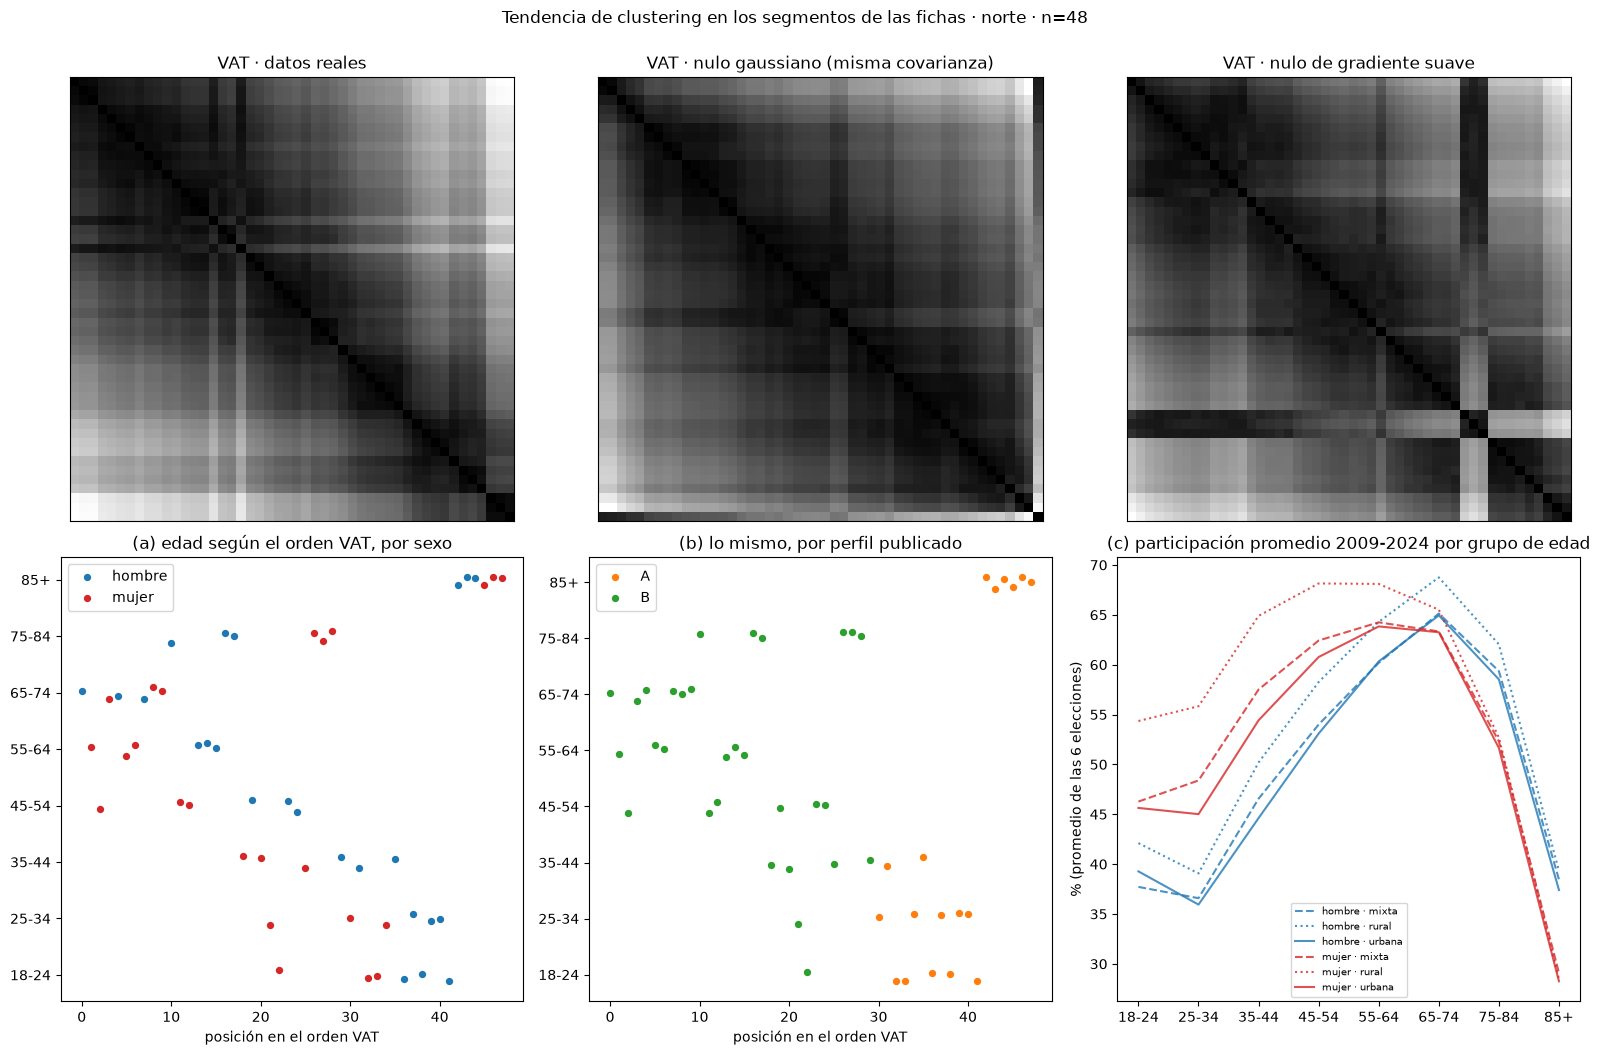

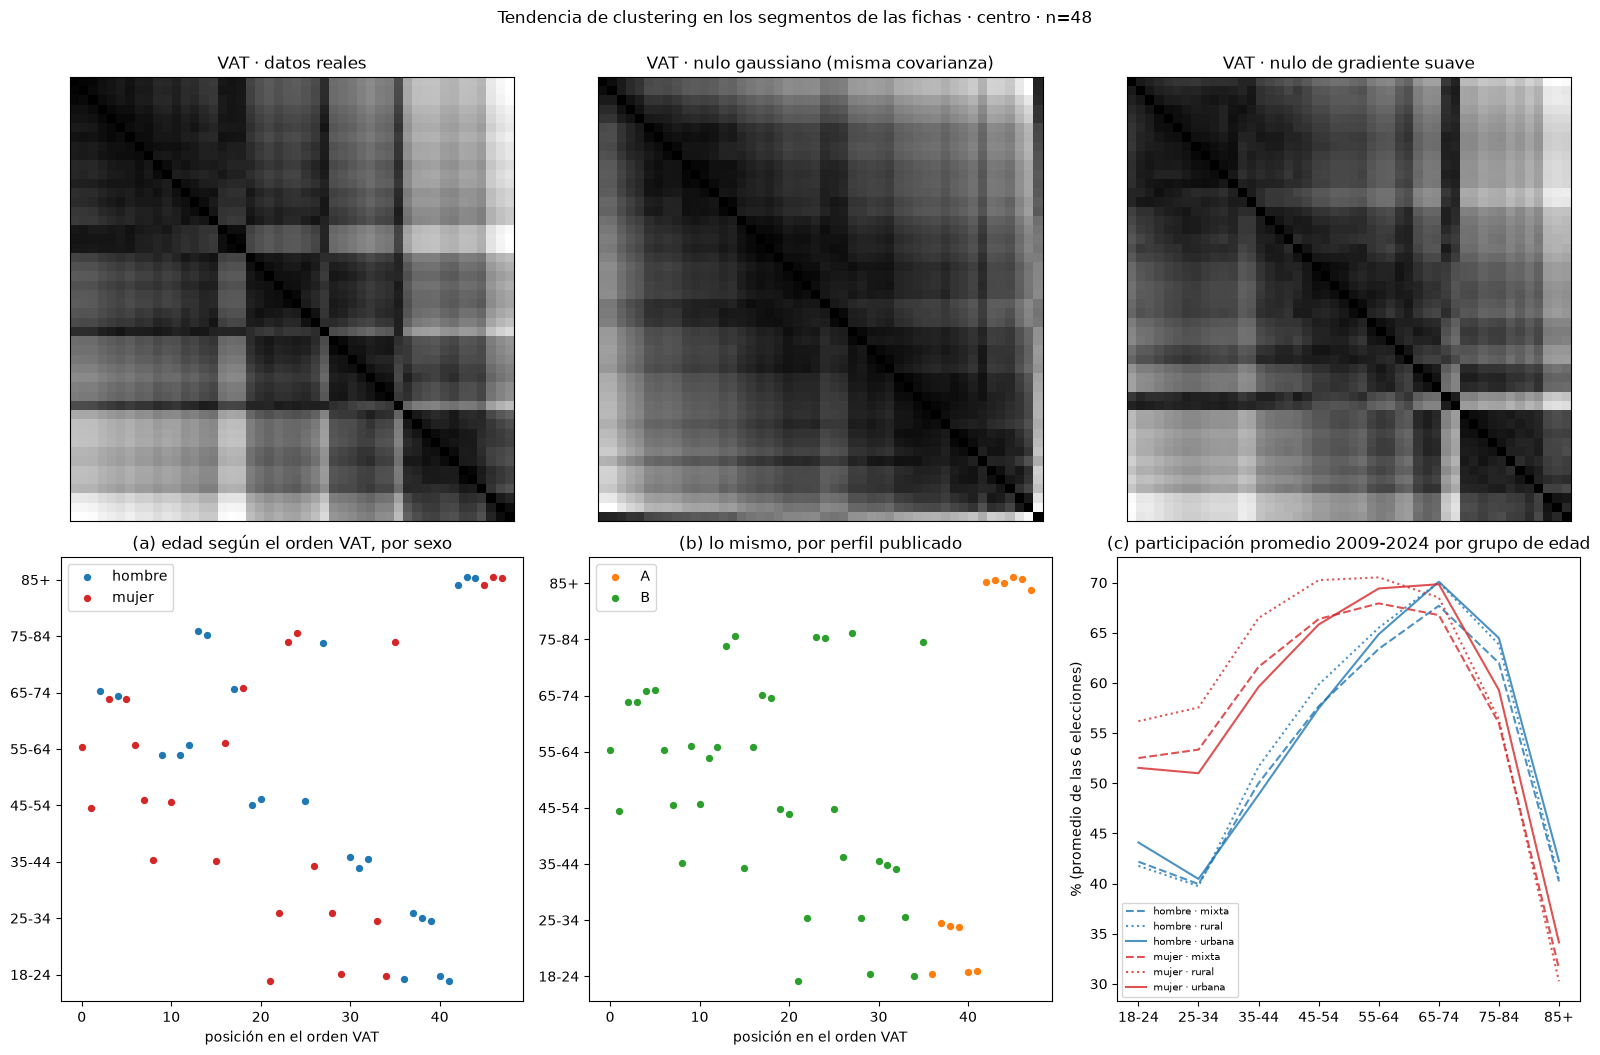

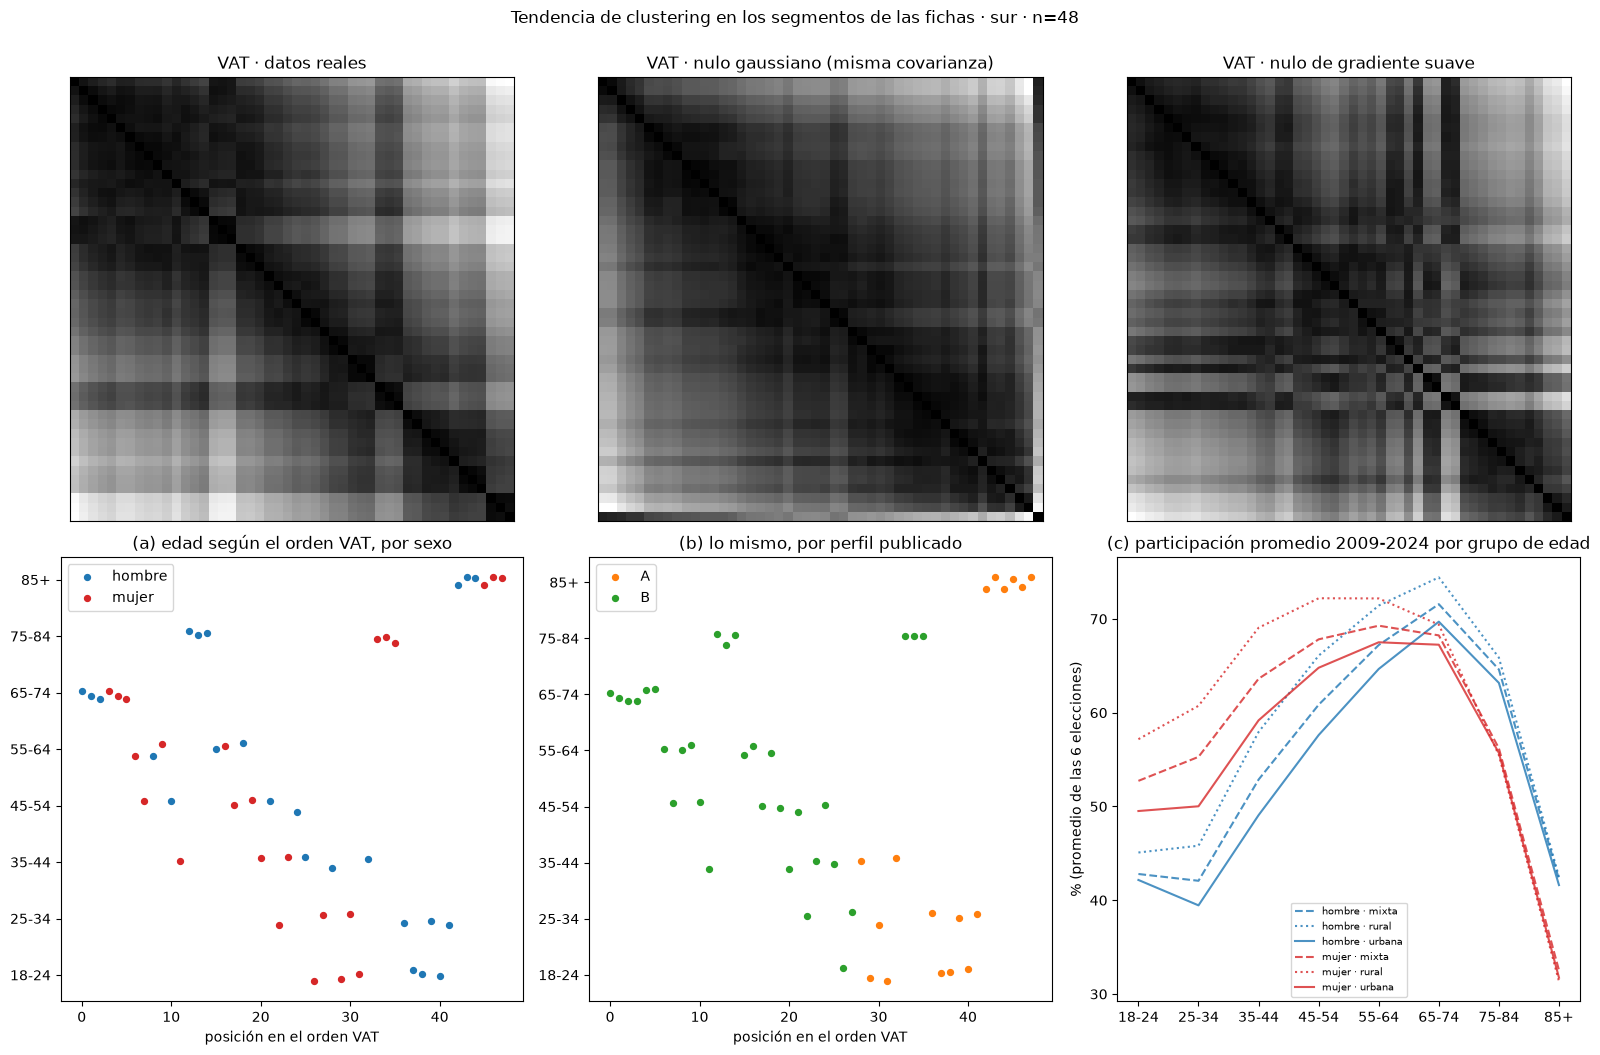

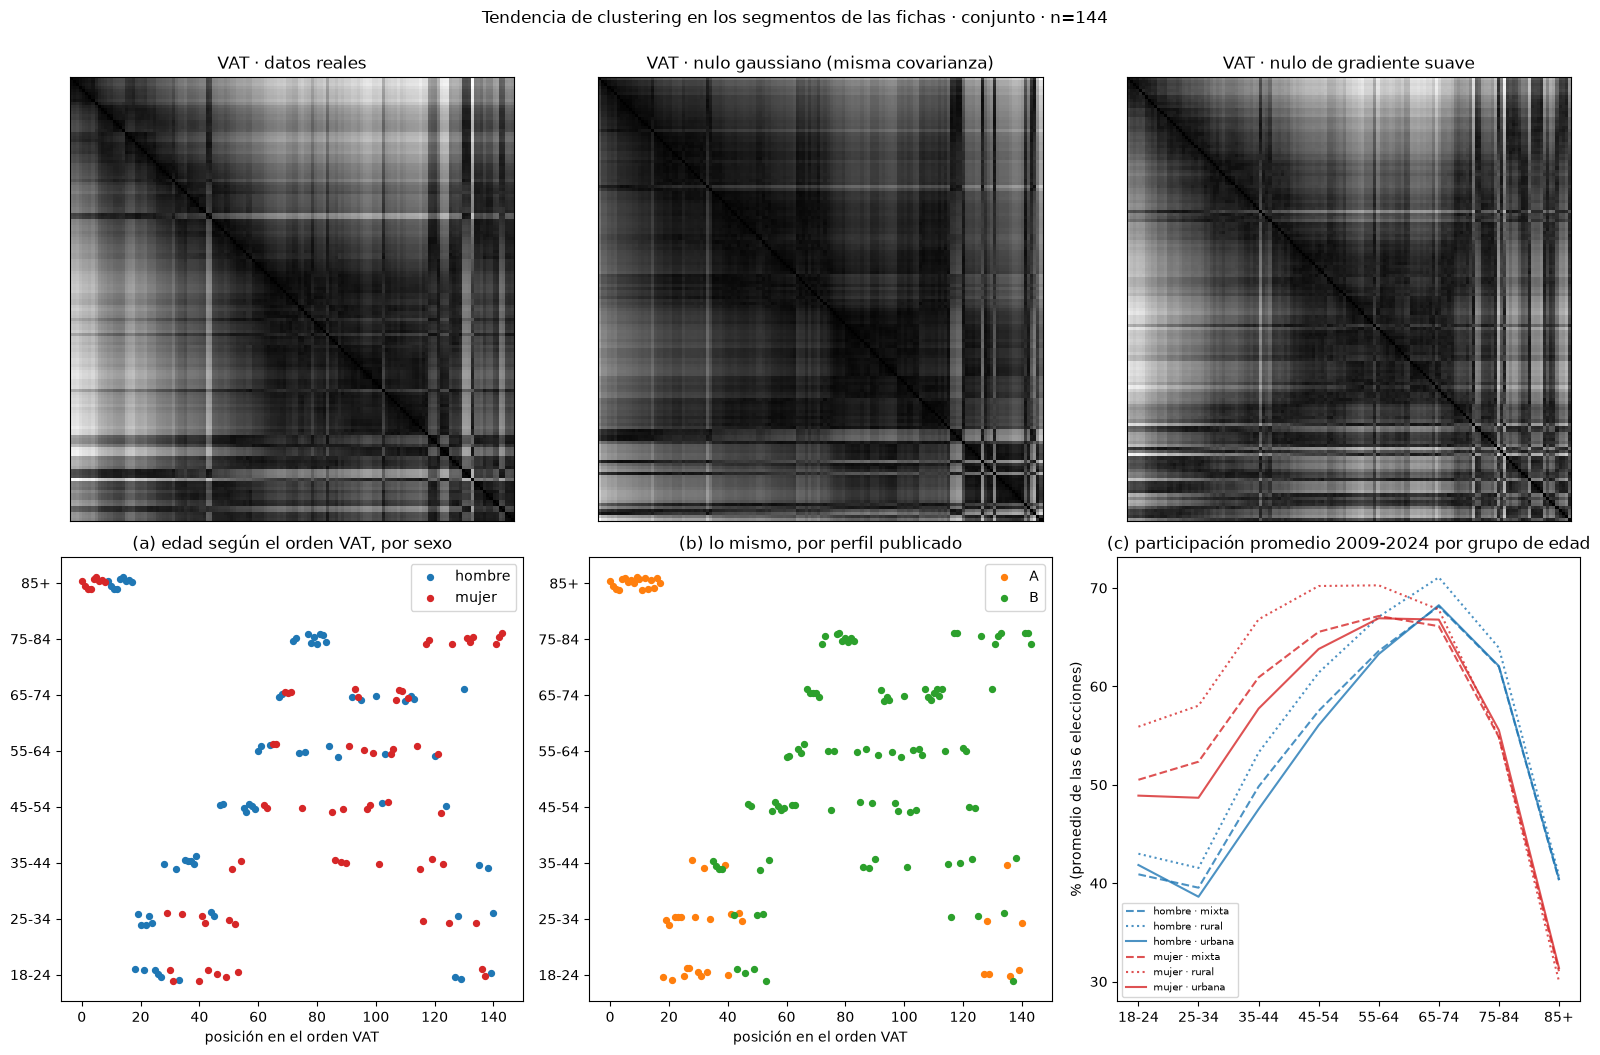

In [7]:
col_sexo = {'hombre': '#1f77b4', 'mujer': '#d62728'}
col_perf = {'A': '#ff7f0e', 'B': '#2ca02c'}
for case, frame in cases.items():
    Z = Zs[case]
    Zn = nulo_modelo(*modelos[(case, 'suave')], np.random.default_rng(SEED))
    fig, axs = plt.subplots(2, 3, figsize=(16, 10.5))
    for ax, (X, t) in zip(axs[0], [(Z, 'datos reales'), (nulos(Z)['gauss'], 'nulo gaussiano (misma covarianza)'), (Zn, 'nulo de gradiente suave')]):
        ax.imshow(vat(X)[0], cmap='gray', interpolation='nearest')
        ax.set(title=f'VAT · {t}', xticks=[], yticks=[])
    orden = vat(Z)[1]
    edad = frame.index.get_level_values('grupo_edad').map(AGES.index).to_numpy()[orden]
    sexo = frame.index.get_level_values('sexo').to_numpy()[orden]
    for ax, colores, clave, titulo in ((axs[1, 0], col_sexo, sexo, '(a) edad según el orden VAT, por sexo'),
                                       (axs[1, 1], col_perf, frame.perfil.to_numpy()[orden], '(b) lo mismo, por perfil publicado')):
        for k, c in colores.items():
            m = clave == k
            ax.scatter(np.where(m)[0], edad[m] + np.random.default_rng(0).uniform(-.12, .12, m.sum()), s=18, c=c, label=k)
        ax.set(title=titulo, xlabel='posición en el orden VAT', yticks=range(len(AGES)), yticklabels=AGES)
        ax.legend()
    nivel = frame[COLS].mean(axis=1)
    for (s, sec), g in nivel.groupby([frame.index.get_level_values('sexo'), frame.index.get_level_values('tipo_seccion')]):
        q = g.groupby(g.index.get_level_values('grupo_edad')).mean().reindex(AGES)
        axs[1, 2].plot(range(len(AGES)), q.values, c=col_sexo[s], ls={'urbana': '-', 'mixta': '--', 'rural': ':'}[sec], alpha=.8, label=f'{s} · {sec}')
    axs[1, 2].set(title='(c) participación promedio 2009-2024 por grupo de edad', xticks=range(len(AGES)), xticklabels=AGES, ylabel='% (promedio de las 6 elecciones)')
    axs[1, 2].legend(fontsize=7)
    fig.suptitle(f'Tendencia de clustering en los segmentos de las fichas · {case} · n={len(Z)}', y=1.0)
    fig.tight_layout()
    fig.savefig(OUT / f'vat_fichas_{case}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 8. Autopruebas
1. Hopkins sobre datos uniformes ≈ 0.5.
2. Hopkins sobre dos nubes bien separadas > 0.85.
3. `vat` devuelve una permutación válida.
4. El nulo de modelo con ruido 0 reproduce el ajuste, y el ajuste recupera exactamente una tabla que ya está en el espacio del modelo (la prueba detecta lo que debe).
5. Una tabla con una separación artificial en dos grupos sí sube Hopkins por encima del nulo.

In [8]:
rng = np.random.default_rng(SEED)
h_unif = hopkins(rng.uniform(size=(600, 3)))[0]
h_blobs = hopkins(np.vstack([rng.normal(0, .3, (300, 3)), rng.normal(5, .3, (300, 3))]))[0]
assert 0.4 < h_unif < 0.6, h_unif
assert h_blobs > 0.85, h_blobs
assert sorted(vat(rng.normal(size=(50, 3)))[1]) == list(range(50))

f = frames['norte']
mu, sd = modelos[('norte', 'suave')]
assert np.allclose(nulo_modelo(mu, np.zeros_like(sd), rng), mu)
assert np.allclose(nulo_modelo(mu, np.zeros((6, 6)), rng), mu)
assert np.allclose(np.cov(nulo_modelo(np.zeros((20000, 6)), modelos_cov[('norte', 'suave')][1], rng).T), modelos_cov[('norte', 'suave')][1], atol=0.02)   # el ruido con covarianza reproduce la covarianza pedida
mu2, sd2 = ajusta(mu, f, 'suave')                  # una tabla ya generada por el modelo se recupera sin residuo
assert np.allclose(mu2, mu) and sd2.max() < 1e-8
Zinj = mu + 4 * (np.arange(len(mu)) % 2)[:, None]  # dos grupos artificiales separados
assert hopkins(Zinj)[0] > hopkins(nulo_modelo(*ajusta(Zinj, f, 'suave'), rng))[0] + 0.05, 'Hopkins no detecta grupos artificiales'
print(f'Hopkins uniforme={h_unif:.3f} (≈0.5) · dos nubes={h_blobs:.3f} (>0.85) · VAT y nulos ok')

Hopkins uniforme=0.494 (≈0.5) · dos nubes=0.965 (>0.85) · VAT y nulos ok


## 9. Conclusiones

_Resultados de la ejecución con `perfiles_segmentos.csv` del 2026-10-29 (semilla 42; Hopkins con 200 repeticiones; nulos con 50 realizaciones; silhouette con 200). Si cambia el agrupamiento publicado, volver a ejecutar y revisar este texto._

**Veredicto formal (regla fijada antes de ejecutar, con ruido independiente): ambiguo en las tres regiones.** Con una sensibilidad agregada después, que modela mejor el ruido, la ambigüedad se resuelve hacia **sin estructura más allá del gradiente por edad** (con una salvedad en el norte).

1. **Validación.** La tabla es la misma que se agrupó: 144 filas (48 por región), silhouette de k = 2 y agrupamiento (ARI = 1) iguales a las fichas con el algoritmo elegido por región (norte y sur k-means, centro Ward), y una celda (norte, hombres, 18–24, mixta, 2009 = 31.793 %) igual al maestro.
2. **Hopkins es igual al de una nube gaussiana.** H real = 0.831 a 0.867 (0.865–0.867 en el conjunto); `delta_gauss` entre −0.022 y −0.001. Las columnas permutadas dan 0.51 a 0.55, así que H es alto por la forma alargada de la nube (las 6 tasas muy correlacionadas), no por grupos. Es el mismo resultado de los otros notebooks.
3. **Contra los nulos de gradiente, el resultado formal es ambiguo.** `delta_suave` entre +0.051 y +0.070 (`delta_celdas` entre +0.041 y +0.061), por encima del umbral de "sin estructura" (0.05) pero lejos del de "estructura" (0.10); y la silhouette real (0.596 a 0.617) supera el percentil 95 del nulo `suave` en las tres regiones (centro por muy poco: p = 0.04).
4. **Ese exceso desaparece con un ruido mejor modelado.** Los nulos del punto 3 agregan ruido independiente por elección, pero los residuos reales están correlacionados entre elecciones y por eso la tabla real es más "delgada". Con ruido de covarianza completa, `delta` baja a +0.005 a +0.019 y la silhouette real queda dentro de los nulos en centro (p = 0.30–0.40) y sur (p = 0.14–0.22). En el norte queda en el borde (0.617 frente a un percentil 95 de 0.614–0.615; p = 0.045). Este análisis se agregó después de ver el primer resultado, así que **no sustituye** al veredicto formal.
5. **La silhouette de 0.6 no es evidencia de grupos.** Una tabla sin grupos con la misma estructura por edad y sexo ya da una silhouette mediana de 0.55 a 0.59; la gaussiana da 0.51 a 0.53. La silhouette real (0.596 a 0.617) apenas supera eso. Esto repite, con los datos de las fichas, lo que muestra la sección 4.2 del `README.md` de esta carpeta.
6. **Lo que ordena los segmentos es la edad.** En cada región, la edad explica el 80–81 % de la varianza de las 6 tasas; sexo × edad, 94–96 %; el sexo solo, 1–3.5 %; la sección, 2–4 %; y la región (en el conjunto), 4.4 %. Una regla de solo edad reproduce el 87.5–91.7 % de las asignaciones de perfil (la referencia es 62.5–75 %). La NMI del perfil con la edad es 0.30–0.34, con el sexo ≤ 0.07 y con la sección ≤ 0.02.
7. **Los dos perfiles de las fichas son cortes de edad.** El perfil A contiene siempre los 85+ (6 de 6 segmentos en cada región) y entre la mitad (centro) y cinco de seis (norte y sur) de los segmentos de 18–34; el perfil B contiene siempre los de 45–84. La participación promedio 2009–2024 forma una U invertida: ≈44–49 % a los 18–34, máximo de 65–70 % a los 65–74 y 33–37 % a los 85+. En el VAT del norte, los segmentos 85+ forman un bloque pequeño y separado al final del orden, y el perfil A ocupa el extremo de baja participación.
8. **Posible efecto de agrupar la edad.** Los 85+ son un solo grupo (85–99 años), de modo que se ve como un salto de ≈24 puntos entre 75–84 y 85+ (60.3 % a 36.5 % en el centro). Con la edad simple, el notebook de los 164 segmentos no encuentra un salto ahí (contraste ≈ 1). Es coherente con que la separación del bloque 85+ se deba en parte al tamaño del grupo de edad, pero **no se probó con esta tabla**.

**Qué implica.** Con la tabla de las fichas tampoco hay evidencia de grupos naturales: los dos perfiles por región son cortes del gradiente por edad, igual que los cuatro de `perfiles_sexo_edad`. La excepción a vigilar es la silhouette del norte, que queda en el borde de lo esperado sin grupos.

**Limitaciones.** El nulo `suave` supone un polinomio de grado 4 en la edad (solo 8 grupos, así que no permite probar continuidad a lo largo de la edad; para eso está el notebook de los 164 segmentos). Los resultados del punto 4 dependen de haber cambiado el modelo de ruido después de ver el primer resultado. Con 48 puntos por región Hopkins es ruidoso (se reporta con `m` = 10 y 5; con 144 puntos en el conjunto). La tabla está agregada por región: no descarta estructura por entidad o municipio.